# 42b · Project: MPC by predictive sampling, a mobile robot crossing a crowded room
The PID drone (project 42) reacted to the error **now**. Model predictive control (MPC) asks a different question
every control step: *"of all the things I could do over the next 2 seconds, which works out best?"* It simulates the
candidates with a model, picks the cheapest, executes only its first action, and asks again 0.1 s later.

We use **predictive sampling**, the sampling-based MPC behind MuJoCo MPC (Howell et al., 2022): no gradients, no
solver, just "perturb the current plan, roll every candidate forward, keep the best". It runs in a few ms with numpy.

**The task:** the Stanford TidyBot (Menagerie) crosses a 6 m room while five people walk back and forth across its
path. The base takes velocity commands limited to 1 m/s and **1.5 m/s² acceleration**: it can't stop instantly, so
reacting late means a collision.

In [1]:
import time, numpy as np, matplotlib.pyplot as plt
from vlacourse import show_video, wilson
from vlacourse import showcase as sc
from vlacourse.mpc_nav import (CrowdRoom, ReactiveController, PredictiveSampling, constant_velocity, oracle, run, Film,
                               DT, V_MAX, A_MAX, R_BASE, R_PERSON)

room = CrowdRoom(n_people=5)
print(f"base: v_max {V_MAX} m/s, a_max {A_MAX} m/s² -> stopping from full speed takes {V_MAX / A_MAX:.2f} s and {V_MAX ** 2 / (2 * A_MAX):.2f} m")

base: v_max 1.0 m/s, a_max 1.5 m/s² -> stopping from full speed takes 0.67 s and 0.33 m


## 1. The baseline: a potential field (PID + repulsion)
Attraction toward the goal (a P controller on position) plus a repulsive push away from every person closer than
0.9 m, computed from where they are *now*. This is how many real robots still avoid obstacles.

## 2. Predictive sampling
The plan is 20 velocity commands (2 s), parameterized by 5 knots. Every 0.1 s:
1. **candidates:** the previous plan shifted by one step (warm start), "stop", "drive straight at the goal", and 125
   noisy copies of the plan;
2. **rollout:** simulate the base for each candidate (same velocity and acceleration limits as the real one) and
   **predict where the people will be** (default: they keep their current velocity);
3. **cost:** time-integrated distance to the goal + a large penalty inside a 0.25 m safety margin + a small effort term;
4. **execute** the first command of the cheapest candidate.

one MPC step: 128 candidates × 20 steps in 3.1 ms (the budget at 10 Hz is 100 ms)


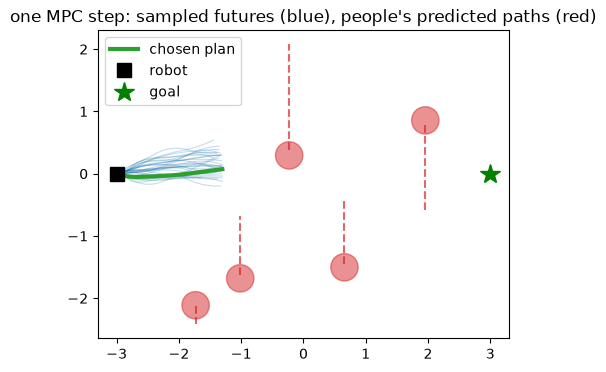

In [2]:
mpc = PredictiveSampling()
o = room.reset(0)
t0 = time.time()
for _ in range(20):
    v, info = mpc(o)
print(f"one MPC step: {128} candidates × {mpc.H} steps in {(time.time() - t0) / 20 * 1000:.1f} ms (the budget at 10 Hz is 100 ms)")

fig, ax = plt.subplots(figsize=(7, 4))
for i in range(0, 128, 4):
    ax.plot(info["paths"][i, :, 0], info["paths"][i, :, 1], c="tab:blue", alpha=0.25, lw=0.8)
ax.plot(info["paths"][info["best"], :, 0], info["paths"][info["best"], :, 1], c="tab:green", lw=3, label="chosen plan")
pred = constant_velocity(o, o["t"] + np.arange(1, 21) * DT)
for j in range(room.n):
    ax.plot(pred[:, j, 0], pred[:, j, 1], "--", c="tab:red", alpha=0.7)
    ax.add_patch(plt.Circle(o["people"][j], R_PERSON, color="tab:red", alpha=0.5))
ax.plot(*o["pos"], "ks", ms=10, label="robot"); ax.plot(*o["goal"], "g*", ms=15, label="goal")
ax.set_aspect("equal"); ax.legend(loc="upper left"); ax.set_title("one MPC step: sampled futures (blue), people's predicted paths (red)")
plt.show()

## 3. Head to head: 20 crowd scenarios
Same rooms (people's speeds and phases are random per scenario), same base limits. Success = reach the goal with
zero contact.

In [3]:
def evaluate(ctrl, n=20):
    R = [run(room, ctrl, 1000 + s) for s in range(n)]
    k = sum(r["reached"] and r["collisions"] == 0 for r in R)
    return dict(k=k, n=n, ci=wilson(k, n), collided=sum(r["collisions"] > 0 for r in R),
                time=np.mean([r["time"] for r in R if r["reached"]] or [np.nan]), clear=np.mean([r["min_clear"] for r in R]))

controllers = {
    "reactive (potential field)": ReactiveController(),
    "MPC, constant-velocity prediction": PredictiveSampling(),
    "MPC, + bigger safety margin (0.4 m)": PredictiveSampling(margin=0.4),
    "MPC, + longer horizon (3 s)": PredictiveSampling(margin=0.4, horizon=30),
    "MPC, perfect prediction (oracle)": PredictiveSampling(margin=0.4, predictor=oracle(room)),
}
results = {}
for name, ctrl in controllers.items():
    t0 = time.time(); results[name] = r = evaluate(ctrl)
    print(f"{name:38s} success {r['k']:2d}/20 (CI {r['ci'][0]:.2f}-{r['ci'][1]:.2f}) | collided in {r['collided']:2d} | "
          f"crossing time {r['time']:.1f} s | mean closest approach {100 * r['clear']:+.0f} cm ({time.time() - t0:.0f}s)")

reactive (potential field)             success  5/20 (CI 0.11-0.47) | collided in 15 | crossing time 10.0 s | mean closest approach -14 cm (3s)


MPC, constant-velocity prediction      success 16/20 (CI 0.58-0.92) | collided in  4 | crossing time 10.4 s | mean closest approach +10 cm (8s)


MPC, + bigger safety margin (0.4 m)    success 16/20 (CI 0.58-0.92) | collided in  4 | crossing time 11.4 s | mean closest approach +21 cm (9s)


MPC, + longer horizon (3 s)            success 14/20 (CI 0.48-0.85) | collided in  6 | crossing time 11.1 s | mean closest approach +20 cm (10s)


MPC, perfect prediction (oracle)       success 18/20 (CI 0.70-0.97) | collided in  2 | crossing time 11.4 s | mean closest approach +27 cm (9s)


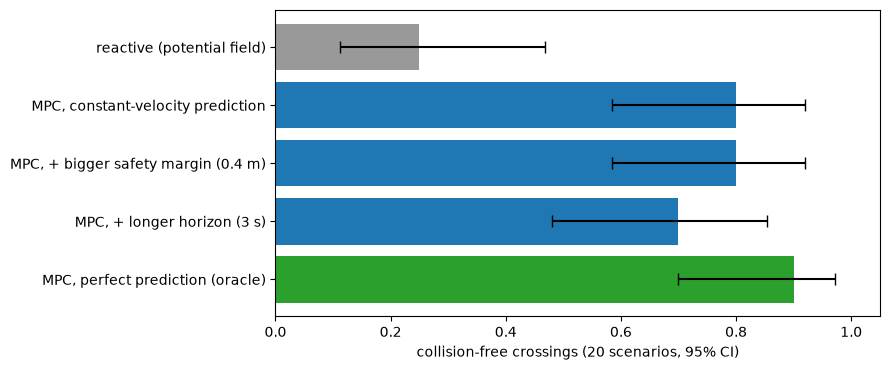

In [4]:
names = list(results)
k = np.array([results[n]["k"] for n in names]) / 20; ci = np.array([results[n]["ci"] for n in names])
plt.figure(figsize=(9, 3.8))
plt.barh(names, k, xerr=np.clip([k - ci[:, 0], ci[:, 1] - k], 0, None), capsize=4, color=["#999", "tab:blue", "tab:blue", "tab:blue", "tab:green"])
plt.gca().invert_yaxis(); plt.xlim(0, 1.05); plt.xlabel("collision-free crossings (20 scenarios, 95% CI)"); plt.tight_layout(); plt.show()

How to read it:
- **Prediction beats reaction: 5/20 → 16/20.** The potential field only feels a person when they are already
  close; with a base that needs 0.33 m to stop, that's too late. MPC sees the collision coming 2 s ahead and slows
  or swerves early.
- **MPC is only as good as its model of the future.** People here walk back and forth; "they keep their current
  velocity" is wrong whenever someone turns around. With the true future (an oracle no real robot has), the same
  MPC does better (18/20) and keeps the widest berth (+27 cm). Even then it's not perfect: with this acceleration
  limit, some situations can't be escaped once the robot is in them. Better prediction (a learned pedestrian model)
  is where real crowd navigation improves.
- **A safety margin buys clearance, not success here:** the closest approach doubles (+10 → +21 cm) for a crossing
  that is 1 s slower; the success count doesn't change.
- **A longer horizon is not free:** 3 s instead of 2 s *hurts* (14/20), because 3-second constant-velocity
  predictions are even more wrong. Horizon length should match how far ahead your model can actually see.
- With 20 scenarios the confidence intervals of the MPC rows overlap: only the reactive-vs-MPC gap is certain.

## 4. Share-ready video
The same scenario, reactive vs MPC. In the MPC view you see the robot "think": faint blue lines are sampled futures,
the green line is the plan it chose.

In [5]:
def film_run(ctrl, seed, label):
    fm, frames = Film(room), []
    def on_step(r, o, info):
        for f in fm.frames(info):                                    # 3 interpolated frames per 0.1 s control step
            f = sc.caption(f, label, where="top", size=24)
            frames.append(sc.badge(f, f"t = {r.t:4.1f} s · contacts {r.collisions}", corner="tr", size=20))
    res = run(room, ctrl, seed, on_step=on_step)
    ok = res["reached"] and res["collisions"] == 0
    end = sc.badge(frames[-1], "✓ crossed safely" if ok else f"✗ {res['collisions']} contact steps", corner="bl", size=28, color=sc.GOOD if ok else sc.BAD)
    return frames + [end] * 60, ok

# a scenario where the reactive controller collides and MPC doesn't (fall back to the first one)
cands = [s for s in range(1000, 1020) if run(room, ReactiveController(), s)["collisions"] > 0 and run(room, PredictiveSampling(margin=0.4), s)["collisions"] == 0]
seed = cands[0] if cands else 1000
a, ok_a = film_run(ReactiveController(), seed, "reactive potential field (PID + repulsion)")
b, ok_b = film_run(PredictiveSampling(margin=0.4), seed, "MPC by predictive sampling (128 futures / step)")
T = max(len(a), len(b)); a += [a[-1]] * (T - len(a)); b += [b[-1]] * (T - len(b))
intro = sc.title_card("Crossing a crowded room", "reactive control vs model predictive control\nMuJoCo · Stanford TidyBot (Menagerie)", size=(720, 1280), n=75)
video = intro + a + b                          # one after the other, full 1280x720 each
show_video(video, fps=30, title="42b MPC crowd navigation HD", width=960)
sc.export(video, "outputs/42b_mpc_crowd_navigation.mp4", fps=30)

saved outputs/42b_mpc_crowd_navigation.mp4  (7.0 MB)


['outputs/42b_mpc_crowd_navigation.mp4']

## Exercises
1. **Better prediction:** people here move as $y = A\sin(\omega t + \phi)$. Fit $A, \omega, \phi$ from the last 2 s of
   observations and use it as the `predictor`. How close do you get to the oracle?
2. **Samples vs time:** sweep `n_samples` (16, 64, 256). Plot success and compute time. Where is the knee?
3. **A faster robot:** set `A_MAX = 3.0` in `vlacourse.mpc_nav`. Does the reactive controller catch up? Why?
4. **MPC for the drone:** replace the drone racer's carrot-chasing PID with predictive sampling over thrust and
   torque plans. What does it do differently before a sharp turn?